# STAGE 2 — TASK 1: PCA | HomeOffice

## 1. Đọc dữ liệu và chuẩn hóa 5 đặc trưng

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pathlib import Path
from IPython.display import display

# Đặt file JSON cùng thư mục notebook, hoặc chỉnh DATA_PATH nếu cần
df = pd.read_json("clean_data.json")
features = ["price_vnd", "rating_num", "length_cm", "width_cm", "height_cm"]
X = df[features].apply(pd.to_numeric, errors="coerce")
print("Kích thước dataset:", df.shape)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Đặc trưng dùng trong mô hình:", features)
display(df[["product_id"] + features].head())

Kích thước dataset: (336, 14)
Đặc trưng dùng trong mô hình: ['price_vnd', 'rating_num', 'length_cm', 'width_cm', 'height_cm']


,product_id,price_vnd,rating_num,length_cm,width_cm,height_cm
0,HBON015,3800000,4,120.0,80.0,75.0
1,HBTC055,7300000,1,360.0,120.0,75.0
2,HBXC069,6400000,4,180.0,80.0,75.0
3,HBRT141,6750000,3,160.0,70.0,75.0
4,HBCO083,2280000,5,120.0,60.0,76.0


## 2. PCA và lựa chọn số thành phần
PCA thực hiện trên dữ liệu **đã chuẩn hóa**. Chọn số thành phần nhỏ nhất có phương sai tích lũy ≥ 85%; nếu giá trị vượt 95% do bước nhảy rời rạc giữa các thành phần, ghi nhận thay vì ép giảm.

In [2]:
# PCA đầy đủ để phân tích phương sai
pca_full = PCA()
pca_full.fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
variance_table = pd.DataFrame({
    "Thành phần": [f"PC{i+1}" for i in range(len(explained))],
    "Explained Variance Ratio": explained,
    "Cumulative Explained Variance": cumulative
})
display(variance_table.round(5))

# Chọn số PC ít nhất đạt 85%; nếu vượt 95% thì ghi rõ lý do
n_components = int(np.searchsorted(cumulative, 0.85) + 1)
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(X_pca, columns=[f"PC{i+1}" for i in range(n_components)], index=df.index)
kept = float(pca.explained_variance_ratio_.sum())
print(f"Chọn {n_components} PC; giữ lại {kept:.2%} phương sai.")
if kept > 0.95:
    print("Lưu ý: mức giữ lại vượt 95% do thêm thành phần cuối để đạt ngưỡng tối thiểu 85%.")


,Thành phần,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.33938,0.33938
1,PC2,0.26463,0.60401
2,PC3,0.19973,0.80374
3,PC4,0.11342,0.91715
4,PC5,0.08285,1.00000


Chọn 4 PC; giữ lại 91.72% phương sai.


## 3. Biểu đồ Explained Variance và Cumulative Variance

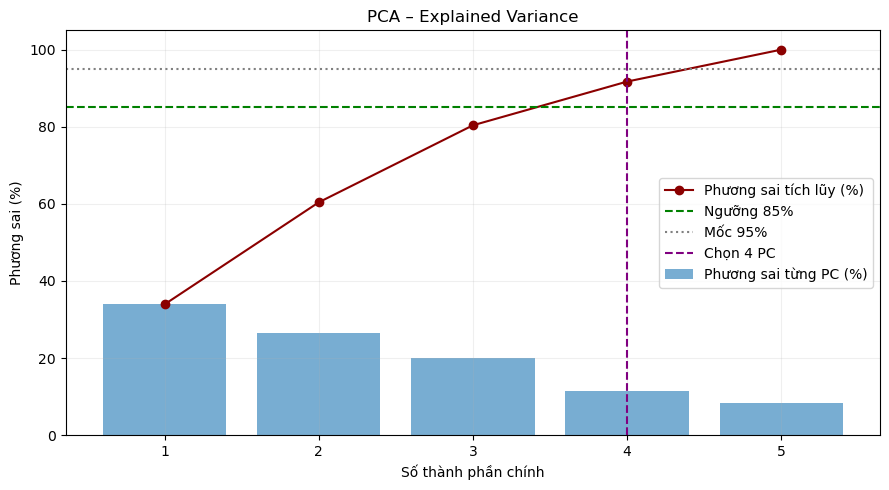

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
x_axis = np.arange(1, len(explained)+1)
ax.bar(x_axis, explained*100, alpha=0.6, label="Phương sai từng PC (%)")
ax.plot(x_axis, cumulative*100, marker="o", color="darkred", label="Phương sai tích lũy (%)")
ax.axhline(85, linestyle="--", color="green", label="Ngưỡng 85%")
ax.axhline(95, linestyle=":", color="gray", label="Mốc 95%")
ax.axvline(n_components, linestyle="--", color="purple", label=f"Chọn {n_components} PC")
ax.set_xticks(x_axis); ax.set_xlabel("Số thành phần chính")
ax.set_ylabel("Phương sai (%)"); ax.set_title("PCA – Explained Variance")
ax.legend(); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

## 4. Trực quan dữ liệu trong không gian PCA

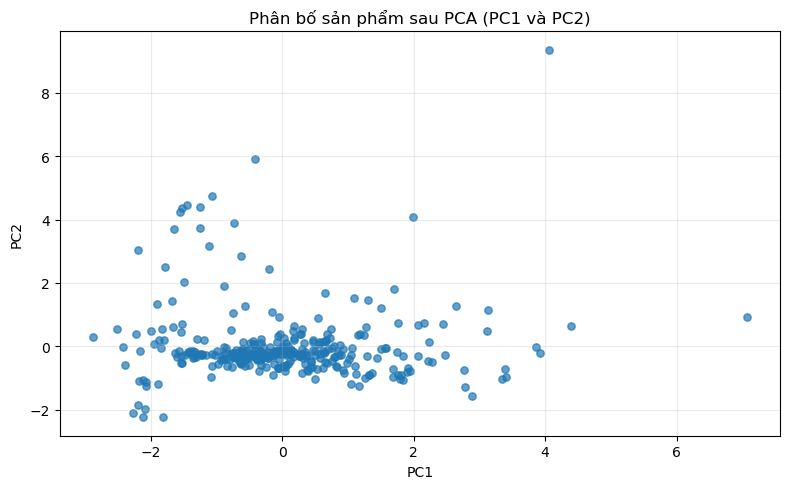

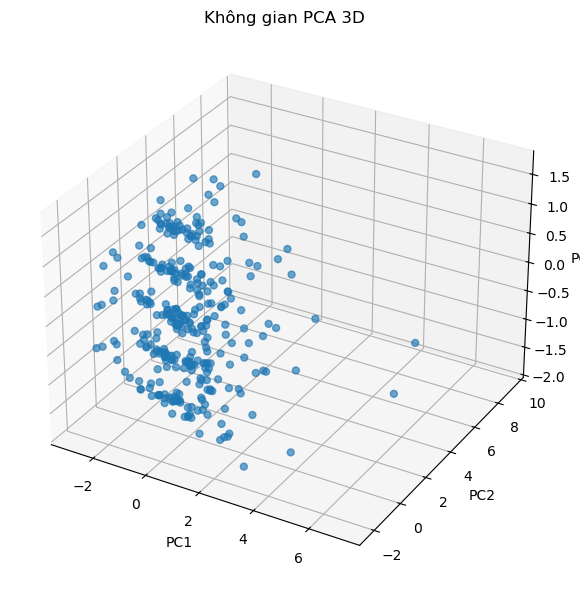

In [4]:
if n_components >= 2:
    plt.figure(figsize=(8, 5))
    plt.scatter(X_pca[:, 0], X_pca[:, 1], s=28, alpha=0.7)
    plt.xlabel("PC1"); plt.ylabel("PC2")
    plt.title("Phân bố sản phẩm sau PCA (PC1 và PC2)")
    plt.grid(alpha=0.25); plt.tight_layout(); plt.show()
else:
    plt.figure(figsize=(8, 4))
    plt.scatter(X_pca[:, 0], np.zeros(len(X_pca)), alpha=0.6)
    plt.xlabel("PC1"); plt.title("Phân bố sản phẩm trên PC1")
    plt.tight_layout(); plt.show()
if n_components >= 3:
    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], alpha=0.65, s=25)
    ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title="Không gian PCA 3D")
    plt.tight_layout(); plt.show()

## 5. Đóng góp của đặc trưng gốc vào từng thành phần

,PC1,PC2,PC3,PC4
price_vnd,0.4686,0.5593,-0.0028,-0.3600
rating_num,0.0718,0.0231,0.9946,0.0600
length_cm,0.6520,-0.1344,-0.0449,-0.3873
width_cm,0.5902,-0.2411,-0.0733,0.7369
height_cm,-0.0432,0.7813,-0.0577,0.4168


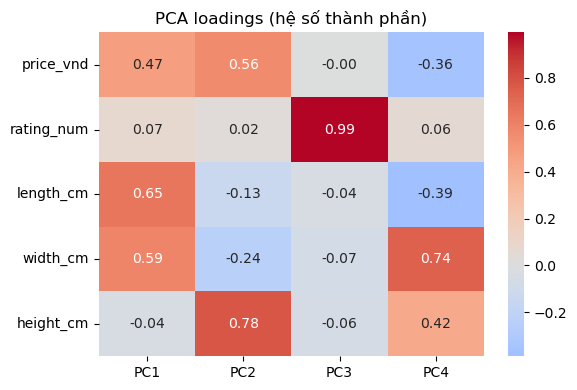

In [5]:
loadings = pd.DataFrame(pca.components_.T, index=features,
                        columns=pca_df.columns)
display(loadings.round(4))
plt.figure(figsize=(max(6, n_components*1.3), 4))
sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("PCA loadings (hệ số thành phần)")
plt.tight_layout(); plt.show()

## 6. Kết luận Task 1 và xuất kết quả

In [6]:
from pathlib import Path
Path("Task5_Streamlit/artifacts").mkdir(parents=True, exist_ok=True)

print(f"Số sản phẩm: {len(df)} | Số biến gốc: {len(features)}")
print(f"PCA: {n_components} thành phần; giữ lại {kept:.2%} phương sai.")
print("Giữ nguyên 336 sản phẩm, không tự ý sửa số đo nguồn.")

# Xuất dữ liệu chuẩn hóa và PCA theo cùng thứ tự sản phẩm
scaled_export = pd.DataFrame(X_scaled, columns=features)
scaled_export.insert(0, "product_id", df["product_id"].to_numpy())
scaled_export.to_csv("Task5_Streamlit/artifacts/homeoffice_features_scaled.csv", index=False, encoding="utf-8-sig")

pca_export = pca_df.copy().reset_index(drop=True)
pca_export.insert(0, "product_id", df["product_id"].to_numpy())
pca_export.to_csv("Task5_Streamlit/artifacts/homeoffice_pca_transformed.csv", index=False, encoding="utf-8-sig")

variance_table.to_csv("Task5_Streamlit/artifacts/homeoffice_pca_variance_report.csv", index=False, encoding="utf-8-sig")
print("Đã xuất 3 file CSV dùng cho Task 2 và Streamlit.")
print("\nKẾT LUẬN TASK 1:")
print(f"Từ {len(features)} đặc trưng ban đầu, PCA chọn {n_components} thành phần, giữ {kept:.2%} phương sai.")
print("Dữ liệu được chuẩn hóa để tránh giá VNĐ lấn át kích thước và rating.")
print("Các thành phần được giữ sẽ dùng làm đầu vào cho Task 2.")


Số sản phẩm: 336 | Số biến gốc: 5
PCA: 4 thành phần; giữ lại 91.72% phương sai.
Giữ nguyên 336 sản phẩm, không tự ý sửa số đo nguồn.
Đã xuất 3 file CSV dùng cho Task 2 và Streamlit.

KẾT LUẬN TASK 1:
Từ 5 đặc trưng ban đầu, PCA chọn 4 thành phần, giữ 91.72% phương sai.
Dữ liệu được chuẩn hóa để tránh giá VNĐ lấn át kích thước và rating.
Các thành phần được giữ sẽ dùng làm đầu vào cho Task 2.


## Kết luận Task 1 — dựa trên dữ liệu mới

- Dữ liệu gồm **336 sản phẩm**, với **5 đặc trưng số**: `price_vnd`, `rating_num`, `length_cm`, `width_cm`, `height_cm`.
- Sau `StandardScaler`, PCA chọn **4 thành phần chính** để đạt ngưỡng tối thiểu 85%, giữ **91.72% phương sai**.
- Phép giảm chiều từ 5 xuống 4 thành phần giúp tạo biểu diễn gọn hơn, nhưng vẫn mất khoảng **8.28%** phương sai.
- **Kết luận:** có thể dùng 4 thành phần PCA cho Task 2; cần đối chiếu hiệu quả phân cụm với dữ liệu chuẩn hóa chưa PCA thay vì mặc định PCA tốt hơn.
- **Giới hạn:** một số giá trị kích thước được hiệu chỉnh từ nguồn ghi đơn vị chưa nhất quán; việc đạt đủ 5 cột số không chứng minh mọi giá trị gốc đều chính xác.